## Assignment 3 - Fashion-MNIST Classification

## PART A
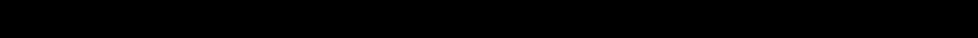

Importing the relevant libraries.

In [4]:
import tensorflow as tf
import pandas as pd
from sklearn.model_selection import train_test_split

The next code is from the assignment description

In [5]:
# Load Fashion-MNIST
(X_train, y_train), (X_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

# Normalize pixel values to [0, 1]
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Flatten 28 x 28 images into 784 features
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 4us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step 
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Splitting train and test:

In [6]:
# 90 % train, 10 % validation. Testdata is held seperate.
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.1, random_state=42
)

print("Train:     ", X_train.shape)
print("Validation:", X_val.shape)
print("Test:      ", X_test.shape)

Train:      (54000, 784)
Validation: (6000, 784)
Test:       (10000, 784)


Code that build and train a model.

In [7]:
def build_and_train(neurons, activation, optimizer):
    tf.keras.utils.set_random_seed(42)  # same starting-point every time

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(784,)),                      # 784 inputs
        tf.keras.layers.Dense(neurons, activation=activation),    # hidden layer
        tf.keras.layers.Dense(10, activation="softmax"),          # output-layer
    ])

    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=optimizer,
        metrics=["accuracy"],
    )

    history = model.fit(
        X_train, y_train,
        epochs=10,
        batch_size=64,
        validation_data=(X_val, y_val),
        verbose=0,
    )
    return model, history

Baseline:

In [8]:
baseline_model, baseline_hist = build_and_train(neurons=32, activation="relu", optimizer="adam")

print("Baseline train accuracy:     ", baseline_hist.history["accuracy"][-1])
print("Baseline validation accuracy:", baseline_hist.history["val_accuracy"][-1])

Baseline train accuracy:      0.8902962803840637
Baseline validation accuracy: 0.875166654586792


Experiment 1, 64 neurons:

In [9]:
exp1_model, exp1_hist = build_and_train(neurons=64, activation="relu", optimizer="adam")

print("Exp 1 train accuracy:     ", exp1_hist.history["accuracy"][-1])
print("Exp 1 validation accuracy:", exp1_hist.history["val_accuracy"][-1])

Exp 1 train accuracy:      0.8989629745483398
Exp 1 validation accuracy: 0.8811666369438171


Experiment 2, tahn:

In [10]:
exp2_model, exp2_hist = build_and_train(neurons=32, activation="tanh", optimizer="adam")

print("Exp 2 train accuracy:     ", exp2_hist.history["accuracy"][-1])
print("Exp 2 validation accuracy:", exp2_hist.history["val_accuracy"][-1])

Exp 2 train accuracy:      0.8952777981758118
Exp 2 validation accuracy: 0.8776666522026062


Experiment 3, SGD:

In [11]:
exp3_model, exp3_hist = build_and_train(neurons=32, activation="relu", optimizer="sgd")

print("Exp 3 train accuracy:     ", exp3_hist.history["accuracy"][-1])
print("Exp 3 validation accuracy:", exp3_hist.history["val_accuracy"][-1])

Exp 3 train accuracy:      0.8512222170829773
Exp 3 validation accuracy: 0.8374999761581421


Result chart:

In [12]:
models = {
    "Baseline":     baseline_model,
    "Experiment 1": exp1_model,
    "Experiment 2": exp2_model,
    "Experiment 3": exp3_model,
}
histories = {
    "Baseline":     baseline_hist,
    "Experiment 1": exp1_hist,
    "Experiment 2": exp2_hist,
    "Experiment 3": exp3_hist,
}

results = pd.DataFrame({
    "Hidden neurons": [32, 64, 32, 32],
    "Activation":     ["relu", "relu", "tanh", "relu"],
    "Optimizer":      ["Adam", "Adam", "Adam", "SGD"],
    "Train accuracy": [h.history["accuracy"][-1] for h in histories.values()],
    "Val accuracy":   [h.history["val_accuracy"][-1] for h in histories.values()],
}, index=list(models.keys()))

results.round(4)

,Hidden neurons,Activation,Optimizer,Train accuracy,Val accuracy
Baseline,32,relu,Adam,0.8903,0.8752
Experiment 1,64,relu,Adam,0.8990,0.8812
Experiment 2,32,tanh,Adam,0.8953,0.8777
Experiment 3,32,relu,SGD,0.8512,0.8375


Best model and test:

In [13]:
# Choose the model with highest validation accuracy
best_name = results["Val accuracy"].idxmax()
best_model = models[best_name]
print("Best model (validation accuracy):", best_name)

# Test only the best model in the test
test_loss, test_acc = best_model.evaluate(X_test, y_test, verbose=0)
print("Test accuracy for", best_name, ":", round(test_acc, 4))

Best model (validation accuracy): Experiment 1
Test accuracy for Experiment 1 : 0.8739


## PART B

**Q1 Architecture and parameters**

Hidden layer: 784 × 32 weights + 32 biases = 25,088 + 32 = 25,120.
Output layer: 32 × 10 weights + 10 biases = 320 + 10 = 330.
Total trainable parameters = 25,450.

Parameters (weights and biases) are the values the model learns by itself during training. Hyperparameters are settings we choose before training, such as the number of neurons, activation function, optimizer, number of epochs and batch size.

**Q2 Activation and loss**

ReLU is used in the hidden layer because it is simple and fast to compute, and it adds the non-linearity the network needs to learn more than straight-line patterns. Softmax is used in the output layer because it turns the 10 output values into probabilities that sum to 1, so the model can say how likely each clothing category is. Sparse categorical cross-entropy fits this dataset because it is a multi-class problem (10 classes) where the labels are integers 0–9 and not one-hot vectors. The loss is small when the model gives a high probability to the correct class and large when it is confidently wrong.

**Q3 Training and Keras function**

model.compile() sets up the model for training by choosing the loss function, the optimizer and the metrics. model.fit() trains the model on the training data for a given number of epochs and batch size. model.evaluate() measures loss and accuracy on a dataset, for example validation or test data. model.predict() returns the model’s output (class probabilities) for new images. Backpropagation calculates how much each weight contributed to the error (the gradients), and the optimizer uses these gradients to update the weights so the loss gets smaller.

**Q4 Interpreting your experiments**

Experiment 1 (64 neurons) achieved the highest validation accuracy, 0.8812, compared to 0.8752 for the baseline. Using tanh also gave a small improvement (0.8777), but the difference from the baseline is small. Changing the optimizer to SGD made the result clearly worse (0.8375), so not every change improved accuracy. SGD with default settings learns slower than Adam, so after only 10 epochs it had not reached the same accuracy.

## Part C

Confusion Matrix:

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step  


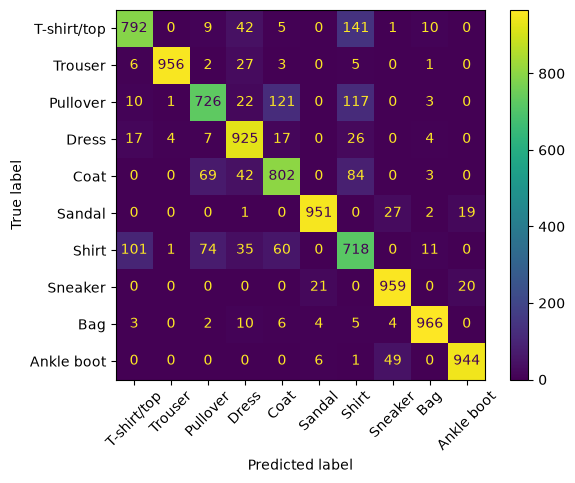

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Predictions on the test set using the best model
y_pred = np.argmax(best_model.predict(X_test), axis=1)

# Create and show the confusion matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(xticks_rotation=45)
plt.show()

In [17]:
cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)   # remove correct predictions, we only want to see the errors
true_class, pred_class = np.unravel_index(cm_errors.argmax(), cm_errors.shape)

print(f"Most confused: {class_names[true_class]} is wrongly predicted as {class_names[pred_class]}")
print("Number of times:", cm_errors[true_class, pred_class])

Most confused: T-shirt/top is wrongly predicted as Shirt
Number of times: 141
